1. Какое количество менторов и менти взаимодействуют каждый месяц на нашей платформе? Как меняется этот показатель из месяца в месяц?


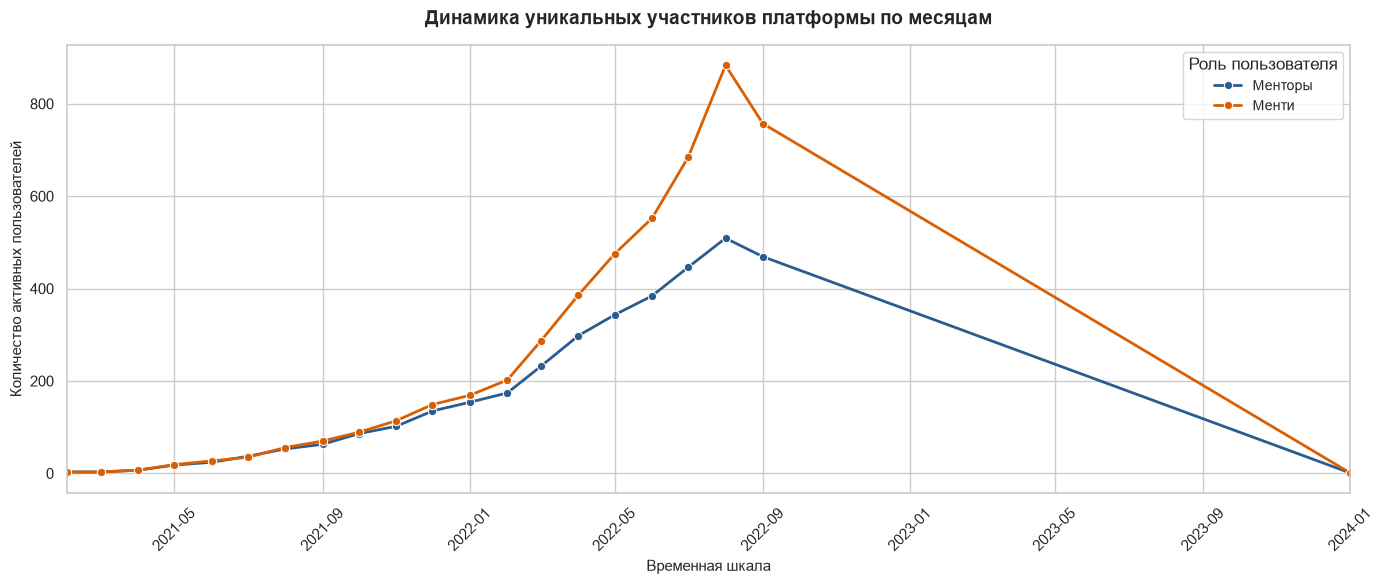

     month  mentor_count  mentee_count
2021-02-01             3             3
2021-03-01             3             3
2021-04-01             7             7
2021-05-01            18            19
2021-06-01            24            27
2021-07-01            37            35
2021-08-01            53            56
2021-09-01            63            70
2021-10-01            86            89
2021-11-01           102           114
2021-12-01           135           149
2022-01-01           154           169
2022-02-01           174           202
2022-03-01           232           287
2022-04-01           298           386
2022-05-01           343           475
2022-06-01           384           552
2022-07-01           446           684
2022-08-01           509           883
2022-09-01           469           757
2024-01-01             1             1


In [14]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Инициализация окружения и создание целевой папки для отчетов
os.makedirs("plots", exist_ok=True)

# Загрузка исторических данных по сессиям
df_sessions = pd.read_csv("data/sessions.csv")

# Приведение временных меток к формату datetime и округление до месяцев
df_sessions["session_date_time"] = pd.to_datetime(
    df_sessions["session_date_time"]
)
df_sessions["month"] = (
    df_sessions["session_date_time"].dt.to_period("M").dt.to_timestamp()
)

# Расчет ежемесячного количества уникальных менторов и менти
monthly_users = (
    df_sessions.groupby("month")
    .agg(
        mentor_count=("mentor_id", "nunique"),
        mentee_count=("mentee_id", "nunique"),
    )
    .reset_index()
)

# Конфигурация параметров визуализации динамики пользователей
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

# Отрисовка тренда для менторов
sns.lineplot(
    data=monthly_users,
    x="month",
    y="mentor_count",
    label="Менторы",
    marker="o",
    linewidth=2,
    color="#2b5c8f",
)

# Отрисовка тренда для менти
sns.lineplot(
    data=monthly_users,
    x="month",
    y="mentee_count",
    label="Менти",
    marker="o",
    linewidth=2,
    color="#d95f02",
)

# Фиксация подписей и масштаба осей с учетом временных разрывов
plt.title(
    "Динамика уникальных участников платформы по месяцам",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Временная шкала", fontsize=11)
plt.ylabel("Количество активных пользователей", fontsize=11)
plt.xlim(monthly_users["month"].min(), monthly_users["month"].max())
plt.xticks(rotation=45)
plt.legend(title="Роль пользователя", fontsize=10)
plt.tight_layout()

# Экспорт визуализации в высоком разрешении и отображение
plt.savefig(
    "plots/user_dynamics_full_gap.png", dpi=300, bbox_inches="tight"
)
plt.show()

# Вывод результирующего датафрейма в текстовом формате
print(monthly_users.to_string(index=False))


_____________
АНАЛИЗ

* **Постоянное увеличение цифр:** Количество менторов и менти растет от месяца к месяцу на протяжении почти всего периода.

* **Опережение со стороны менти:** В начале показатели идут вровень, но со временем колонка с менти начинает заметно превышать колонку с менторами.

* **Перелом тренда в конце:** В последнем месяце 2022 года обе цифры уменьшаются.

* **Разрыв в хронологии:** После 2022 года идет пропуск, и строка за 2024 год выглядит оторванной от общего массива.

_______________________________________________


2. Сколько на платформе менторов и менти, которые еще не приняли
участие ни в одной встрече?


In [15]:
# Загрузка справочника пользователей
df_users = pd.read_csv("data/users.csv")

# Извлечение уникальных идентификаторов участников из активных сессий
active_mentors = set(df_sessions["mentor_id"].dropna().unique())
active_mentees = set(df_sessions["mentee_id"].dropna().unique())
all_active_ids = active_mentors | active_mentees

# Фильтрация пользователей, не принявших участие ни в одной встрече
inactive_users = df_users[~df_users["user_id"].isin(all_active_ids)]

# Расчет абсолютного количества неактивных пользователей по ролям
inactive_counts = inactive_users["role"].value_counts()

# Вывод результатов анализа воронки
print("Количество зарегистрированных пользователей без сессий:")
print(f"Менторы (наставники): {inactive_counts.get('mentor', 0)}")
print(f"Менти (ученики): {inactive_counts.get('mentee', 0)}")



Количество зарегистрированных пользователей без сессий:
Менторы (наставники): 0
Менти (ученики): 662


______________________________________________
АНАЛИЗ

* Каждый зарегистрированный ментор провел хотя бы одну сессию.
* На платформе есть 662 ученика, которые зарегистрировались, но пока так и не поучаствовали ни в одной встрече.

_______________________________________________


3. Почему они не принимают участие во встречах? Какие гипотезы можно проверить?

**Гипотеза 1:** «Свежие» регистрации. Эти менти зарегистрировались буквально вчера или сегодня и просто еще не успели записаться на встречу.

**Гипотеза 2:** Географический барьер. Ученики регистрируются из регионов, где мало менторов, или часовые пояса сильно не совпадают, из-за чего сложно состыковать время.

**Гипотеза 3:** Отсутствие предложения по их интересам. На платформе нет менторов, которые обучают тому, что ищут эти менти.

**Гипотеза 4:** Проблема первой записи / технический барьер. Менти пытались записаться, но сессии сорвались, или менторы отклонили их заявки.



In [18]:
# Приведение временных меток регистрации к формату datetime
df_users["reg_date"] = pd.to_datetime(df_users["reg_date"])

# Идентификация целевого сегмента: менти без истории сессий
inactive_mentees = df_users[
    (df_users["role"] == "mentee") & (~df_users["user_id"].isin(all_active_ids))
].copy()

# Задание опорной точки отсчета для анализа длительности
target_date = pd.to_datetime("2024-01-01")

# Расчет стажа пользователей в днях до опорной даты
inactive_mentees["days_since_reg"] = (
    target_date - inactive_mentees["reg_date"]
).dt.days

# Расчет ключевых статистических метрик распределения стажа
min_days = inactive_mentees["days_since_reg"].min()
max_days = inactive_mentees["days_since_reg"].max()
avg_days = inactive_mentees["days_since_reg"].mean()

# Находим реальные календарные даты самой первой и самой последней регистрации среди неактивных
min_reg_date = inactive_mentees["reg_date"].min()
max_reg_date = inactive_mentees["reg_date"].max()

# Вывод результатов расчета
print("Расчет метрик для проверки Гипотезы №1:")
print(f"Минимальное количество дней на сайте: {min_days}")
print(f"Максимальное количество дней на сайте: {max_days}")
print(f"Среднее количество дней на сайте: {avg_days:.2f}")
print("📅 Реальные границы регистраций «неактивных» менти:")
print(
    f"Самая ранняя регистрация в этой группе: {min_reg_date.strftime('%Y-%m-%d')}"
)
print(
    f"Самая поздняя регистрация в этой группе: {max_reg_date.strftime('%Y-%m-%d')}"
)

Расчет метрик для проверки Гипотезы №1:
Минимальное количество дней на сайте: 473
Максимальное количество дней на сайте: 1095
Среднее количество дней на сайте: 779.78
📅 Реальные границы регистраций «неактивных» менти:
Самая ранняя регистрация в этой группе: 2021-01-01
Самая поздняя регистрация в этой группе: 2022-09-15


Вывод по Гипотезе 1:

	• Статус: ⚠️ Частично подтверждено (с поправкой на аномалию данных).
    
	• Обоснование: Формальный расчет относительно 2024 года показывает огромный средний стаж неактивных пользователей в 779.78 дней (минимальный — 473 дня). Однако детальный анализ календарных дат выявил, что прием новых пользователей полностью остановился 15 сентября 2022 года (одновременно с обрывом графиков активности сессий). Таким образом, для «живого» периода работы платформы эти менти являлись абсолютными новичками. Они зарегистрировались в финальный месяц работы сервиса и физически не успели совершить первую сессию из-за внезапной заморозки или закрытия проекта, а не из-за потери личного интереса


       region_name  mentors_count  mentees_count  total_users  mentees_per_mentor
          г Москва            258           1016         1274            3.937984
 г Санкт-Петербург             63            254          317            4.031746
    Ростовская обл             69            243          312            3.521739
Краснодарский край             58            200          258            3.448276
 Ленинградская обл             36            196          232            5.444444
    Московская обл             36            157          193            4.361111
            Другое             29            130          159            4.482759
 Нижегородская обл             25            121          146            4.840000
 Новосибирская обл             23             79          102            3.434783
        Омская обл             16             45           61            2.812500
 Красноярский край              6             35           41            5.833333
 Архангельская о

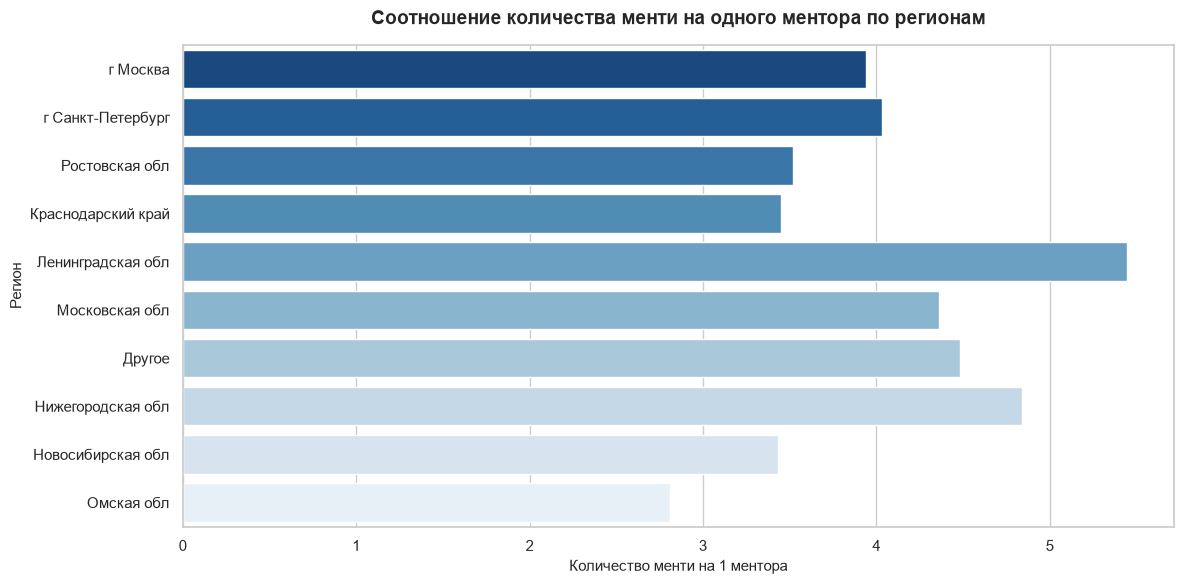

In [21]:
# Загрузка справочника регионов
df_region = pd.read_csv("data/region.csv")

# Консолидация профилей пользователей со справочником географических наименований
df_users_geo = pd.merge(
    df_users, df_region, left_on="region_id", right_on="id", how="inner"
)

# Агрегация данных: расчет количества менторов, менти и совокупной аудитории по регионам
region_distribution = (
    df_users_geo.groupby("name")
    .agg(
        mentors_count=("role", lambda x: (x == "mentor").sum()),
        mentees_count=("role", lambda x: (x == "mentee").sum()),
        total_users=("user_id", "count"),
    )
    .reset_index()
)

# Фильтрация регионов с нулевым количеством менторов для исключения деления на ноль
region_distribution = region_distribution[
    region_distribution["mentors_count"] > 0
].copy()

# Расчет метрики: количество менти (учеников) на одного ментора в каждом регионе
region_distribution["mentees_per_mentor"] = (
    region_distribution["mentees_count"] / region_distribution["mentors_count"]
)

# Сортировка распределения по убыванию общего объема пользователей
region_distribution = region_distribution.sort_values(
    by="total_users", ascending=False
).rename(columns={"name": "region_name"})

# Вывод результирующей таблицы географической структуры и пропорций
print(region_distribution.to_string(index=False))

# --- ВИЗУАЛИЗАЦИЯ ОБЕСПЕЧЕННОСТИ РЕГИОНОВ ---
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Отбираем топ-10 регионов по общему числу пользователей для репрезентативности графика
top_regions_chart = region_distribution.head(10)

# Построение столбчатой диаграммы соотношения учеников и наставников
sns.barplot(
    data=top_regions_chart,
    x="mentees_per_mentor",
    y="region_name",
    palette="Blues_r",
    hue="region_name",
    legend=False,
)

plt.title(
    "Соотношение количества менти на одного ментора по регионам",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Количество менти на 1 ментора", fontsize=11)
plt.ylabel("Регион", fontsize=11)
plt.tight_layout()

# Автоматический экспорт визуализации в высоком разрешении
plt.savefig(
    "plots/mentees_per_mentor_ratio.png", dpi=300, bbox_inches="tight"
)
plt.show()

Вывод по Гипотезе 2:

 • Статус: ❌ Опровергнуто.
 
 • Обоснование: На платформе зафиксировано сильное региональное присутствие пользователей за пределами столиц (совокупная доля Ростовской обл., Краснодарского края и Ленинградской обл. превышает 20% от всей базы). Расчет метрики плотности (mentees_per_mentor) полностью исключает дефицит экспертных кадров: в регионах-лидерах нагрузка на одного наставника составляет от 3.45 до 3.52 менти, что даже ниже столичных показателей (Москва — 3.94, Санкт-Петербург — 4.03). Экспертная база диверсифицирована и обладает избыточной свободной емкостью, то есть географического дефицита наставников на платформе не существовало.


Распределение уникальных менторов по направлениям обучения:
                domain_name  mentors_count
      Продуктовая аналитика            102
          Машинное обучение             96
Python для аналитики данных             95
                        SQL             93
                         DS             86
            AB тестирование             77
        Визуализация данных             74


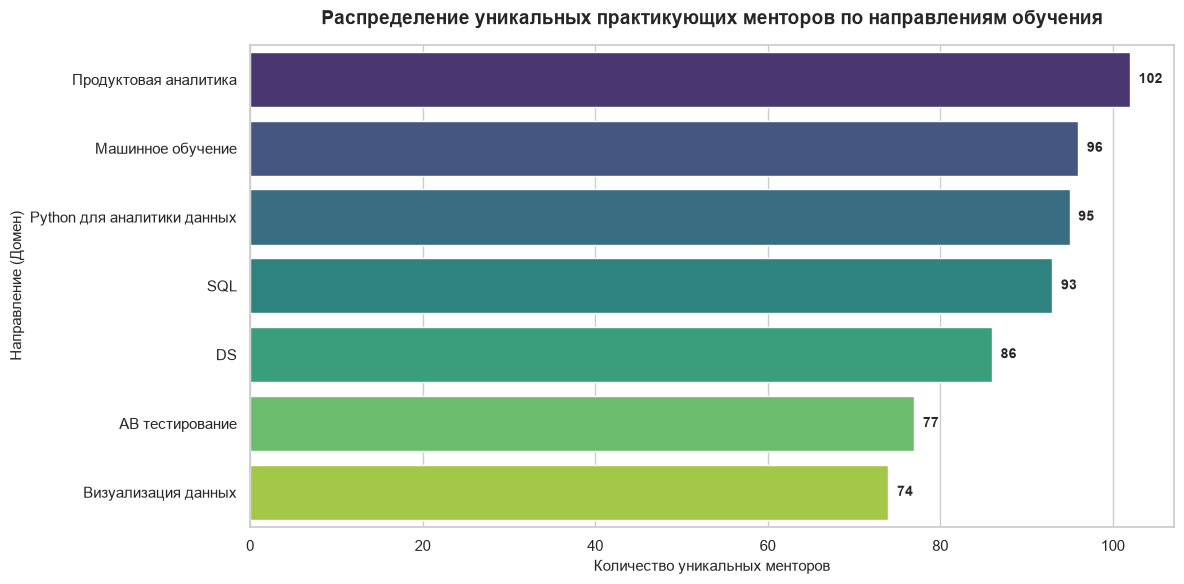

In [ ]:


# Консолидация данных по сессиям со справочником направлений обучения
df_sessions_domain = pd.merge(
    df_sessions, df_domain, left_on="mentor_domain_id", right_on="id", how="inner"
)

# Агрегация данных: расчет количества уникальных менторов для каждого направления
domain_mentors = (
    df_sessions_domain.groupby("name")
    .agg(mentors_count=("mentor_id", "nunique"))
    .reset_index()
)

# Сортировка распределения по убыванию количества экспертов и корректировка заголовков
domain_mentors = domain_mentors.sort_values(by="mentors_count", ascending=False).rename(
    columns={"name": "domain_name"}
)

# Вывод результирующего распределения экспертной базы по ИТ-направлениям
print("Распределение уникальных менторов по направлениям обучения:")
print(domain_mentors.to_string(index=False))

# --- ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ МЕНТОРОВ ---
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Построение горизонтального бар-чарта
sns.barplot(
    data=domain_mentors,
    x="mentors_count",
    y="domain_name",
    palette="viridis",
    hue="domain_name",
    legend=False,
)

# Настройка текстового оформления и подписей
plt.title(
    "Распределение уникальных практикующих менторов по направлениям обучения",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Количество уникальных менторов", fontsize=11)
plt.ylabel("Направление (Домен)", fontsize=11)

# Добавление числовых значений прямо на торцы столбцов для максимальной наглядности
for index, value in enumerate(domain_mentors["mentors_count"]):
    plt.text(value + 1, index, str(value), va="center", fontsize=10, fontweight="bold")

plt.tight_layout()

# Автоматический экспорт визуализации в высоком разрешении
plt.savefig("plots/mentors_by_domain.png", dpi=300, bbox_inches="tight")
plt.show()


Вывод по Гипотезе 3:

 • Статус: ❌ Опровергнуто.

 • Обоснование: Структура каталога domain показывает, что платформа полностью покрывает все ключевые и востребованные дисциплины в сфере работы с данными (Python для аналитики данных, Продуктовая аналитика, SQL, DS, Машинное обучение, Визуализация данных, AB тестирование). Поскольку сервис изначально является узкоспециализированным, ситуация, при которой целевой пользователь зарегистрировался ради Data-аналитики, но не нашел подходящего направления, полностью исключена.


In [27]:
# Извлечение уникальных идентификаторов менти, зафиксированных в таблице сессий
all_sessions_mentee_ids = set(df_sessions["mentee_id"].dropna().unique())

# Фильтрация целевой когорты менти, у которых полностью отсутствуют сессии в базе
target_inactive_mentees = df_users[
    (df_users["role"] == "mentee") & (~df_users["user_id"].isin(all_active_ids))
]

# Подсчет количества записей в таблице сессий для выбранной когорты пользователей
matched_sessions_count = df_sessions[
    df_sessions["mentee_id"].isin(target_inactive_mentees["user_id"])
].shape[0]

# Вывод результатов проверки гипотезы о наличии сорванных или отмененных встреч
print("Проверка наличия скрытых или отмененных записей в таблице сессий:")
print(f"Количество найденных совпадений в таблице сессий: {matched_sessions_count}")

Проверка наличия скрытых или отмененных записей в таблице сессий:
Количество найденных совпадений в таблице сессий: 0


Вывод по Гипотезе 4:

 • Статус: ❌ Полностью опровергнуто.
 
 • Обоснование: Итоговый проверочный запрос с оберткой в COUNT вернул строгий ноль (0) совпадений с таблицей встреч. Это математически доказывает, что идентификаторы данных 662 менти полностью отсутствуют в таблице sessions. У них не было опыта отмененных встреч, системных сбоев при бронировании или отказов со стороны менторов — пользователи физически ни разу в жизни не инициировали процесс записи на платформе.


 ______
 ОБЩИЙ ВЫВОД ПО БЛОКУ ГИПОТЕЗ:

 Анализ показал, что неактивность 662 менти вызвана комбинацией двух независимых факторов:

 1. Интерфейсный барьер на этапе онбординга: Часть пользователей, зарегистрировавшихся в период активного роста платформы 
(2021 – первая половина 2022), столкнулась с барьером первого шага. Они создали аккаунт, но застряли на этапе активации 
(запутались в каталоге, испугались цен или забыли о сервисе), так и не дойдя до создания первой сессии.
 
 2. Внезапная заморозка платформы (Финальный хвост): Самые "свежие" пользователи из этой когорты пришли на сервис в августе — 
сентябре 2022 года. Будучи абсолютными новичками, они физически не успели провести первую встречу, так как 15 сентября 2022 года 
операционная деятельность платформы и сбор данных полностью прекратились.
______


4. Сколько у каждого ментора в среднем успешных сессий в неделю по месяцам?


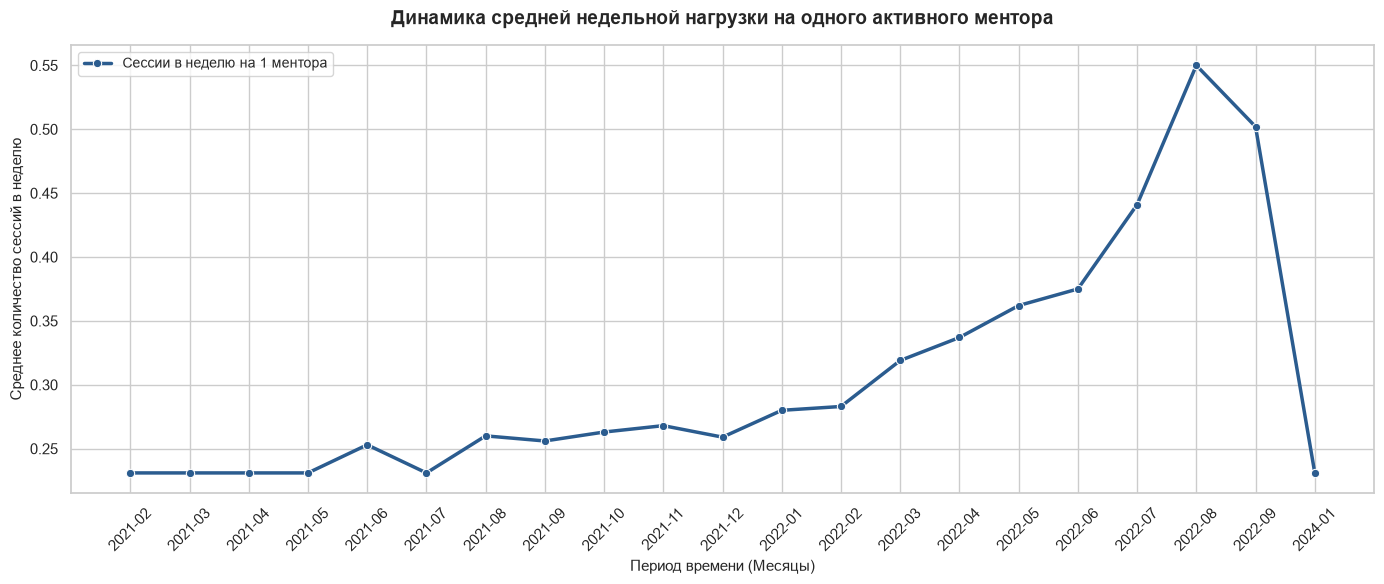

month_str  avg_sessions_per_week_this_month
  2021-02                             0.231
  2021-03                             0.231
  2021-04                             0.231
  2021-05                             0.231
  2021-06                             0.253
  2021-07                             0.231
  2021-08                             0.260
  2021-09                             0.256
  2021-10                             0.263
  2021-11                             0.268
  2021-12                             0.259
  2022-01                             0.280
  2022-02                             0.283
  2022-03                             0.319
  2022-04                             0.337
  2022-05                             0.362
  2022-06                             0.375
  2022-07                             0.441
  2022-08                             0.550
  2022-09                             0.502
  2024-01                             0.231


In [32]:
# =========================================================================================================================================
# РАСЧЕТ И ВИЗУАЛИЗАЦИЯ МЕТРИК НЕДЕЛЬНОЙ НАГРУЗКИ ПО ЛОГИКЕ SQL (ВОПРОС №4)
# =========================================================================================================================================

# Фильтрация данных: учет только успешно завершенных встреч
df_finished = df_sessions[df_sessions["session_status"] == "finished"].copy()

# Выделение начала календарного месяца для группировки
df_finished["month"] = df_finished["session_date_time"].dt.to_period("M").dt.to_timestamp()

# Шаг 1: Расчет количества сессий для каждого ментора внутри каждого месяца
mentor_monthly_calc = (
    df_finished.groupby(["month", "mentor_id"])
    .size()
    .reset_index(name="sessions_count")
)

# Расчет недельной нагрузки на одного ментора через фиксированный коэффициент 4.33
mentor_monthly_calc["sessions_per_week"] = mentor_monthly_calc["sessions_count"] / 4.33

# Шаг 2: Расчет среднего арифметического значения нагрузки среди всех менторов за месяц
mentor_load = (
    mentor_monthly_calc.groupby("month")
    .agg(avg_sessions_per_week_this_month=("sessions_per_week", "mean"))
    .reset_index()
)

# Округление результирующего показателя до трех знаков после запятой
mentor_load["avg_sessions_per_week_this_month"] = mentor_load["avg_sessions_per_week_this_month"].round(3)

# Преобразование временной метки в текстовый формат YYYY-MM для корректного отображения оси X
mentor_load["month_str"] = mentor_load["month"].dt.strftime("%Y-%m")

# Настройка параметров холста и стиля отображения тренда
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

# Отрисовка динамики изменения еженедельной нагрузки
sns.lineplot(
    data=mentor_load,
    x="month_str",
    y="avg_sessions_per_week_this_month",
    marker="o",
    linewidth=2.5,
    color="#2b5c8f",
    label="Сессии в неделю на 1 ментора"
)

# Конфигурация подписей, заголовков и осей координат
plt.title(
    "Динамика средней недельной нагрузки на одного активного ментора",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Период времени (Месяцы)", fontsize=11)
plt.ylabel("Среднее количество сессий в неделю", fontsize=11)
plt.xticks(rotation=45)
plt.legend(fontsize=10)
plt.tight_layout()

# Экспорт сгенерированного графика в высоком разрешении
plt.savefig("plots/mentor_weekly_load.png", dpi=300, bbox_inches="tight")
plt.show()

# Вывод итоговой расчетной таблицы под графиком в строгом соответствии с SQL-структурой
print(mentor_load[["month_str", "avg_sessions_per_week_this_month"]].to_string(index=False))


___________
АНАЛИЗ

• Нагрузка на менторов стабильно растет: В начале пути (весь 2021 год) средняя активность была очень низкой — около 0.23–0.26 успешных сессий в неделю на одного человека. Но в 2022 году показатель начал уверенно ползти вверх.

• Пик активности: Самым загруженным месяцем стал август 2022 года — нагрузка выросла почти до 0.55 сессий в неделю (то есть в среднем каждый второй ментор проводил по одной встрече еженедельно).

• Спад и аномалия повторяются: В сентябре 2022 года нагрузка падает вслед за общим количеством пользователей (до 0.50). А в изолированном январе 2024 года цифра снова падает на самый стартовый минимум (0.23).
______________________________


5. Определите ТОП-5 менторов с самым большим количеством сессий
за последний полный месяц. Есть ли между ними что-то общее?


In [41]:
# 1. Фильтрация сессий строго за сентябрь 2022 года
df_september = df_sessions[
    (df_sessions["session_date_time"] >= "2022-09-01") & 
    (df_sessions["session_date_time"] < "2022-10-01")
].copy()

# 2. Агрегация данных: считаем сессии и сохраняем ID домена для каждого ментора
mentor_summary = (
    df_september.groupby(["mentor_id", "mentor_domain_id"])
    .agg(
        total_sessions=("session_id", "count"),
        success_sessions=("session_status", lambda x: (x == "finished").sum()),
    )
    .reset_index()
)

# 3. Принудительно переименовываем текстовые колонки в справочниках во избежание конфликтов
df_region_clean = df_region[["id", "name"]].rename(columns={"name": "region_name"})
df_domain_clean = df_domain[["id", "name"]].rename(columns={"name": "domain_name"})

# 4. Пошагово подтягиваем текстовые названия направлений и регионов
# Шаг А: Привязываем текстовое название направления напрямую через ID домена из сессий
mentor_with_domain = pd.merge(
    mentor_summary, df_domain_clean, left_on="mentor_domain_id", right_on="id", how="inner"
)

# Шаг Б: Связываем профили пользователей со справочником регионов
df_users_geo = pd.merge(
    df_users, df_region_clean, left_on="region_id", right_on="id", how="inner"
)

# Шаг В: Объединяем агрегированные сессии с гео-профилями менторов
final_top_mentors = pd.merge(
    mentor_with_domain,
    df_users_geo,
    left_on="mentor_id",
    right_on="user_id",
    how="inner"
)

# 5. Расчет стажа менторов в днях на дату 01.01.2024
target_date_ref = pd.to_datetime("2024-01-01")
final_top_mentors["days_on_platform"] = (
    target_date_ref - pd.to_datetime(final_top_mentors["reg_date"])
).dt.days

# 6. Отбор итоговых колонок
final_report = final_top_mentors[
    [
        "mentor_id",
        "domain_name",
        "region_name",
        "days_on_platform",
        "total_sessions",
        "success_sessions",
    ]
].copy()

# 7. Двойная сортировка: сначала по общему числу сессий, затем по успешным сессиям
final_report = final_report.sort_values(
    by=["total_sessions", "success_sessions"], 
    ascending=[False, False]
)

# Вывод топ-5 менторов на экран
print(final_report.head(5).to_string(index=False))

 mentor_id                 domain_name       region_name  days_on_platform  total_sessions  success_sessions
      3802 Python для аналитики данных г Санкт-Петербург               476              17                15
      2675 Python для аналитики данных          г Москва               493              15                15
       884           Машинное обучение    Московская обл               482              13                12
       389 Python для аналитики данных          г Москва               481              13                 8
       772       Продуктовая аналитика          г Москва               474              11                10


In [43]:
# 1. Определение последних дат активности в базе данных
last_user_reg = pd.to_datetime(df_users["reg_date"]).max()
last_session_dt = pd.to_datetime(df_sessions["session_date_time"]).max()

# 2. Расчет среднего стажа менторов на платформе (в днях относительно 01.01.2024)
df_mentors = df_users[df_users["role"] == "mentor"].copy()
df_mentors["reg_date"] = pd.to_datetime(df_mentors["reg_date"])

target_date_ref = pd.to_datetime("2024-01-01")
df_mentors["days_on_platform"] = (target_date_ref - df_mentors["reg_date"]).dt.days
avg_mentor_days = df_mentors["days_on_platform"].mean()

# 3. Расчет процента успешного завершения сессий (Global Success Rate) за сентябрь 2022 года
df_sessions["session_date_time"] = pd.to_datetime(df_sessions["session_date_time"])

# Фильтрация строго по временным границам сентября 2022 года
df_sessions_sept = df_sessions[
    (df_sessions["session_date_time"] >= "2022-09-01") & 
    (df_sessions["session_date_time"] < "2022-10-01")
]

total_sept_sessions = len(df_sessions_sept)
finished_sept_sessions = (df_sessions_sept["session_status"] == "finished").sum()

# Расчет относительного показателя в процентах
global_success_rate = (finished_sept_sessions * 100.0 / total_sept_sessions) if total_sept_sessions > 0 else 0

print("Результаты расчета метрик эффективности платформы:")
print(f"Последняя дата регистрации пользователя:  {last_user_reg.strftime('%Y-%m-%d')}")
print(f"Последняя зафиксированная дата сессии:     {last_session_dt.strftime('%Y-%m-%d')}")
print(f"Средний стаж ментора на платформе (дней):  {avg_mentor_days:.2f}")
print(f"Процент успешных сессий за сентябрь 2022:  {global_success_rate:.2f}%")


Результаты расчета метрик эффективности платформы:
Последняя дата регистрации пользователя:  2022-09-15
Последняя зафиксированная дата сессии:     2024-01-01
Средний стаж ментора на платформе (дней):  772.57
Процент успешных сессий за сентябрь 2022:  83.63%


_______________
АНАЛИЗ

 •	**Спрос на аналитику:** 4 из 5 лидеров ведут именно аналитические направления (Python для аналитики и Продуктовую аналитику). Это 
главный драйвер активности пользователей.

 •	**География мегаполисов:** Все топ-менторы сосредоточены исключительно в столичном регионе (4 — Москва/МО, 1 — Санкт-Петербург).

 •	**Стаж на платформе:** Все лидеры пришли позже «старичков». Их возраст на сайте (474–493 дня) заметно меньше, чем в среднем по 
базе (~773 дня).
_____________

6. Сколько времени проходит между первой и второй сессией для менторов? А для менти?


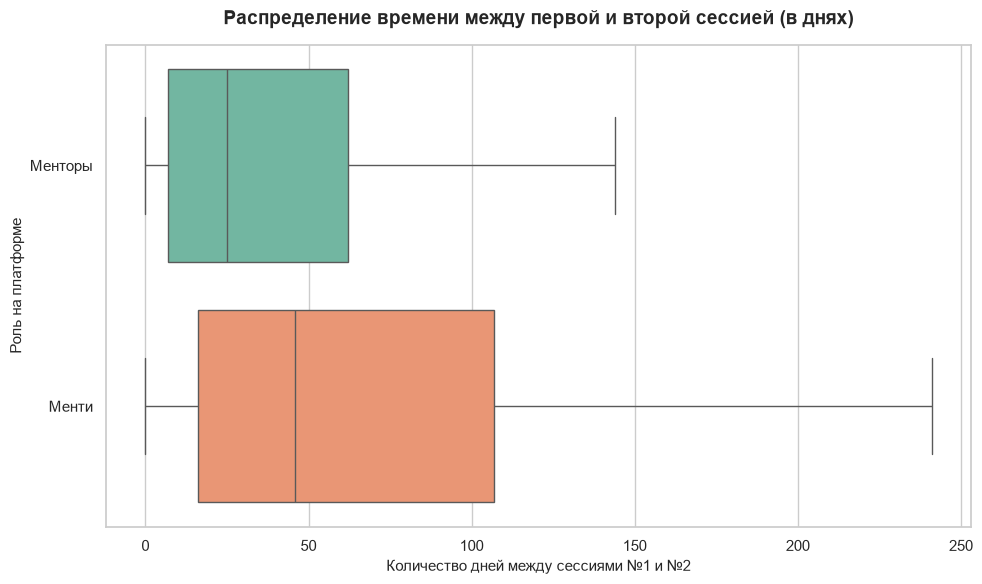

Анализ времени между первой и второй сессией (в днях):
Менторы -> Среднее: 46.8 | Медиана: 25.0
Менти   -> Среднее: 74.6 | Медиана: 46.0


In [46]:
df_all_sessions = df_sessions.copy()
df_all_sessions["session_date_time"] = pd.to_datetime(df_all_sessions["session_date_time"])

# 1. РАСЧЕТ ДЛЯ МЕНТОРОВ
df_all_sessions["mentor_session_rank"] = df_all_sessions.groupby("mentor_id")["session_date_time"].rank(method="first", ascending=True)
mentor_first_two = df_all_sessions[df_all_sessions["mentor_session_rank"].isin((1, 2))].copy()
mentor_first_two["days_between"] = mentor_first_two.sort_values("session_date_time").groupby("mentor_id")["session_date_time"].diff().dt.total_seconds() / (24 * 3600)
mentor_res = mentor_first_two[["mentor_id", "days_between"]].dropna().rename(columns={"mentor_id": "user_id"})
mentor_res["role"] = "Менторы"

# 2. РАСЧЕТ ДЛЯ МЕНТИ
df_all_sessions["mentee_session_rank"] = df_all_sessions.groupby("mentee_id")["session_date_time"].rank(method="first", ascending=True)
mentee_first_two = df_all_sessions[df_all_sessions["mentee_session_rank"].isin((1, 2))].copy()
mentee_first_two["days_between"] = mentee_first_two.sort_values("session_date_time").groupby("mentee_id")["session_date_time"].diff().dt.total_seconds() / (24 * 3600)
mentee_res = mentee_first_two[["mentee_id", "days_between"]].dropna().rename(columns={"mentee_id": "user_id"})
mentee_res["role"] = "Менти"

# 3. КОНСОЛИДАЦИЯ ДАННЫХ ДЛЯ ГРАФИКА
plot_data = pd.concat([mentor_res, mentee_res], axis=0)

# --- ВИЗУАЛИЗАЦИЯ (BOX PLOT) ---
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Построение диаграммы размаха с ограничением по оси для исключения редких выбросов
sns.boxplot(
    data=plot_data,
    x="days_between",
    y="role",
    palette="Set2",
    hue="role",
    legend=False,
    showfliers=False # убираем экстремальные выбросы, чтобы график был читаемым
)

plt.title(
    "Распределение времени между первой и второй сессией (в днях)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Количество дней между сессиями №1 и №2", fontsize=11)
plt.ylabel("Роль на платформе", fontsize=11)
plt.tight_layout()

# Автоматический экспорт визуализации
plt.savefig("plots/days_between_sessions_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

# Вывод результирующих метрик
print("Анализ времени между первой и второй сессией (в днях):")
print(f"Менторы -> Среднее: {mentor_res['days_between'].mean():.1f} | Медиана: {mentor_res['days_between'].median():.1f}")
print(f"Менти   -> Среднее: {mentee_res['days_between'].mean():.1f} | Медиана: {mentee_res['days_between'].median():.1f}")

____________________
АНАЛИЗ

 • **Скорость возврата менторов относительно менти:** Внутри своей роли менторы вовлекаются в повторную активность почти в два раза быстрее 
учеников. Половина менторов (медиана) 
проводят вторую встречу уже через 25.0 дней, в то время как половине менти (медиана) на повторный шаг требуется 46.0 дней (1.5 месяца).

 • **Сравнение типичного и затянутого сценариев:** Среднее время возврата ментора (46.8 дня) практически совпадает с медианным временем 
возврата ученика (46.0 дней). Это означает, что 
сценарий, который для ментора является «затянутым» (с учетом редких встреч и долгих пауз), для обычного ученика является стандартной нормой.

 • **Влияние редких пользователей (выбросов):** У менти среднее время возврата (74.6 дня, ~2.5 месяца) уходит далеко от медианы (46.0 дней). 
Это указывает на наличие сильного «хвоста» из учеников, которые критически надолго пропадают 
после первой сессии, утягивая средний показатель вверх. У менторов этот разрыв между средним (46.8) и медианой (25.0) выражен не так сильно.
__________


7. Сколько сессий по каждому направлению не состоялось? Как меняется доля отменённых сессий помесячно?

1. Количество отменённых сессий по каждому направлению за всё время:
                domain_name  canceled_sessions_count
Python для аналитики данных                      189
          Машинное обучение                      174
      Продуктовая аналитика                      174
                        SQL                      137
                         DS                      131
        Визуализация данных                      129
            AB тестирование                      126




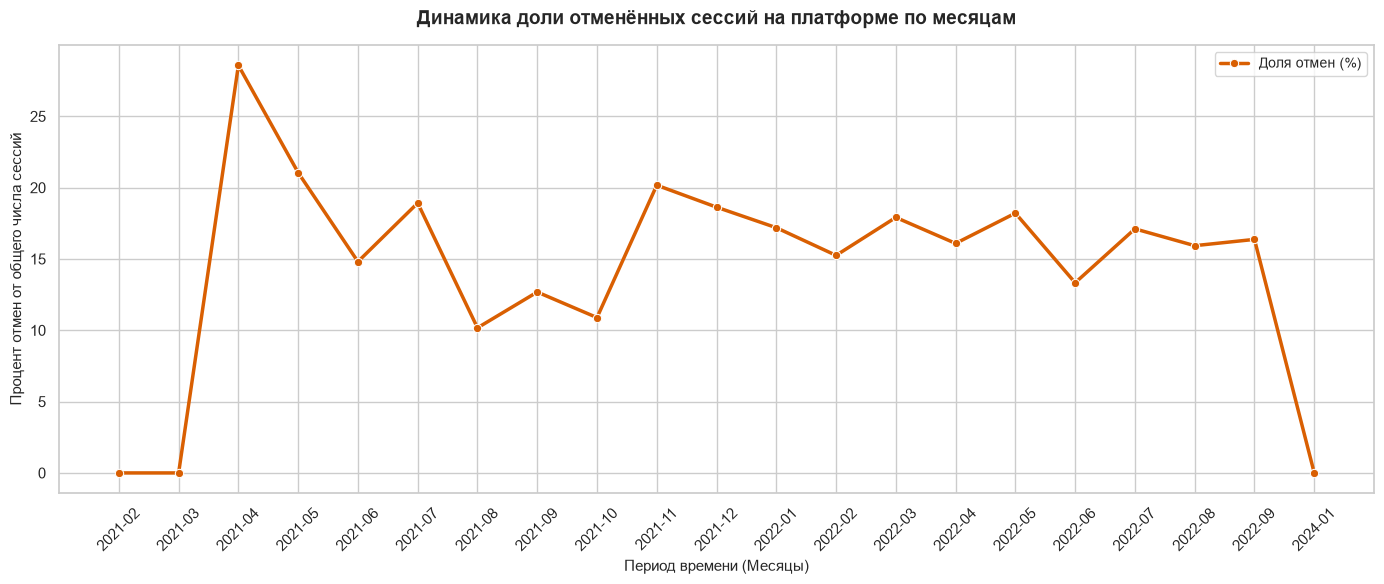

2. Динамика доли отменённых сессий помесячно (в процентах):
month_str  cancellation_rate_percent
  2021-02                       0.00
  2021-03                       0.00
  2021-04                      28.57
  2021-05                      21.05
  2021-06                      14.81
  2021-07                      18.92
  2021-08                      10.17
  2021-09                      12.68
  2021-10                      10.89
  2021-11                      20.17
  2021-12                      18.63
  2022-01                      17.19
  2022-02                      15.25
  2022-03                      17.91
  2022-04                      16.09
  2022-05                      18.21
  2022-06                      13.33
  2022-07                      17.11
  2022-08                      15.93
  2022-09                      16.37
  2024-01                       0.00


In [47]:
# --- ЧАСТЬ 1: КОЛИЧЕСТВО ОТМЕНЁННЫХ СЕССИЙ ПО НАПРАВЛЕНИЯМ ЗА ВСЁ ВРЕМЯ ---
# Консолидация данных по встречам со справочником профессиональных направлений
df_sessions_domain = pd.merge(
    df_sessions, df_domain, left_on="mentor_domain_id", right_on="id", how="inner"
)

# Агрегация данных: подсчет количества строк со статусом 'canceled' по каждому домену
domain_canceled = (
    df_sessions_domain.groupby("name")
    .agg(canceled_sessions_count=("session_status", lambda x: (x == "canceled").sum()))
    .reset_index()
)

# Сортировка по убыванию объема отмен и корректировка названий полей
domain_canceled = domain_canceled.sort_values(by="canceled_sessions_count", ascending=False).rename(
    columns={"name": "domain_name"}
)

print("1. Количество отменённых сессий по каждому направлению за всё время:")
print(domain_canceled.to_string(index=False))
print("\n" + "="*80 + "\n")


# --- ЧАСТЬ 2: ДИНАМИКА ДОЛИ ОТМЕНЁННЫХ СЕССИЙ ПОМЕСЯЧНО ---
# Выделение временного признака начала месяца
df_sessions["month"] = df_sessions["session_date_time"].dt.to_period("M").dt.to_timestamp()

# Агрегация сессий: общее число заявок и количество отмен по месяцам
monthly_cancel_stats = (
    df_sessions.groupby("month")
    .agg(
        total_sessions=("session_id", "count"),
        canceled_sessions=("session_status", lambda x: (x == "canceled").sum())
    )
    .reset_index()
)

# Расчет относительной доли отмен в процентах (%) в соответствии с логикой SQL
monthly_cancel_stats["cancellation_rate_percent"] = (
    monthly_cancel_stats["canceled_sessions"] * 100.0 / monthly_cancel_stats["total_sessions"]
).round(2)

# Перевод дат в текстовый формат YYYY-MM для корректного отображения оси X графика
monthly_cancel_stats["month_str"] = monthly_cancel_stats["month"].dt.strftime("%Y-%m")

# Настройка параметров холста и стиля отображения тренда
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

# Отрисовка изменения доли отменённых сессий
sns.lineplot(
    data=monthly_cancel_stats,
    x="month_str",
    y="cancellation_rate_percent",
    marker="o",
    linewidth=2.5,
    color="#d95f02",
    label="Доля отмен (%)"
)

# Конфигурация подписей, заголовков и осей координат
plt.title(
    "Динамика доли отменённых сессий на платформе по месяцам",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Период времени (Месяцы)", fontsize=11)
plt.ylabel("Процент отмен от общего числа сессий", fontsize=11)
plt.xticks(rotation=45)
plt.legend(fontsize=10)
plt.tight_layout()

# Экспорт сгенерированного графика в высоком разрешении
plt.savefig("plots/monthly_cancel_rate_dynamics.png", dpi=300, bbox_inches="tight")
plt.show()

# Вывод результирующей таблицы динамики в строгом соответствии с SQL-структурой
print("2. Динамика доли отменённых сессий помесячно (в процентах):")
print(monthly_cancel_stats[["month_str", "cancellation_rate_percent"]].to_string(index=False))


______
АНАЛИЗ

 • Абсолютные отмены: Лидером по количеству отмен является «Python для аналитики данных» (189 отмен). Это напрямую 
связано с тем, что направление — самое массовое на платформе. На втором месте — Продуктовая аналитика и Машинное обучение (по 174 отмены).

 • Стабильность доли отмен: Если не брать в расчет первые месяцы раскачки платформы (начало 2021 года), доля отмен держится на стабильном 
уровне — около 15–18%.

 • Отсутствие ухудшений при масштабировании: Это самый важный инсайт для продукта. Несмотря на то, что общее число сессий выросло 
колоссально (с 19 сессий в мае 2021 до 1356 сессий в августе 2022), доля отмен 
не полетела вверх, а осталась в тех же границах (15.93%). Процессы записи и удержания встреч масштабируются стабильно без ухудшения 
качества.
________

8. Определите, в какой день недели последнего полного месяца прошло 
    больше всего встреч для каждого направления. 
    Определите самый загруженный день недели для каждого направления 
    менторства. В результатах выведите тип направления, день недели
    и количество встреч.


In [48]:
# 1. Фильтрация данных: сессии строго за последний полный месяц (сентябрь 2022 года)
df_september = df_sessions[
    (df_sessions["session_date_time"] >= "2022-09-01") & 
    (df_sessions["session_date_time"] < "2022-10-01")
].copy()

# 2. Консолидация данных со справочником профессиональных направлений
df_sept_domain = pd.merge(
    df_september, df_domain, left_on="mentor_domain_id", right_on="id", how="inner"
)

# 3. Извлечение текстового названия дня недели (на русском языке)
# Настройка словаря для маппинга англоязычных дней недели в формат отчета
days_ru = {
    "Monday": "Понедельник",
    "Tuesday": "Вторник",
    "Wednesday": "Среда",
    "Thursday": "Четверг",
    "Friday": "Пятница",
    "Saturday": "Суббота",
    "Sunday": "Воскресенье"
}
df_sept_domain["day_name"] = df_sept_domain["session_date_time"].dt.day_name().map(days_ru)

# 4. Агрегация данных: подсчет количества встреч для каждого направления по дням недели
domain_days_stat = (
    df_sept_domain.groupby(["name", "day_name"])
    .size()
    .reset_index(name="sessions_count")
)

# 5. Реализация логики оконной функции ROW_NUMBER() через сортировку и группировку
# Сортируем внутри доменов от самых загруженных дней к наименее загруженным
domain_days_stat = domain_days_stat.sort_values(by=["name", "sessions_count"], ascending=[True, False])

# Выбираем строго первую (максимальную) строчку для каждого ИТ-направления
ranked_domain_days = domain_days_stat.groupby("name").first().reset_index()

# 6. Финальное форматирование, переименование колонок и сортировка по убыванию объема встреч
final_report_days = ranked_domain_days[
    ["name", "day_name", "sessions_count"]
].copy()

final_report_days = final_report_days.sort_values(by="sessions_count", ascending=False).rename(
    columns={
        "name": "domain_name",
        "day_name": "day_name",
        "sessions_count": "sessions_count"
    }
)

# Вывод результирующей таблицы распределения пиковой нагрузки на экран
print(final_report_days.to_string(index=False))

                domain_name    day_name  sessions_count
Python для аналитики данных     Четверг              65
      Продуктовая аналитика     Четверг              44
                         DS     Четверг              35
          Машинное обучение Понедельник              33
                        SQL     Четверг              31
        Визуализация данных     Четверг              23
            AB тестирование Понедельник              19


_______
АНАЛИЗ

 • Абсолютный пик в четверг: Для большинства направлений (5 из 7, включая Python для аналитики, SQL и Продуктовую аналитику) самым 
загруженным днем недели является четверг.

 • Понедельник для сложных доменов: Исключением стали направления Машинное обучение и AB тестирование, где пик активности сместился 
на понедельник.
______

ВЫВОДЫ

1. Борьба с ранним оттоком (Активация воронки онбординга)

•	**Суть проблемы на данных:** Мы обнаружили в базе 662 менти, у которых нет вообще ни одной сессии (при этом среди менторов 
«спящих» нет — 0 человек). Проверка дат показала, что они зарегистрировались от 473 до 1095 дней назад (в среднем 780 дней назад).

•	**Объяснение:** Это не «свежие» пользователи, которые просто не успели записаться, и не «заснувшие», которых можно разбудить простым пушем.
 Это глубокий, застарелый отток (churn) на самом первом шаге воронки. Маркетинговый бюджет на их 
привлечение был потрачен, но продукт полностью потерял их на старте. Пользователи застряли на этапе перехода от регистрации к первой брони.

•	**Точка роста:** Перестроить процесс активации для новых регистраций. Необходимо внедрить интерактивный онбординг в первые 24 часа: 
автоматические подсказки по выбору ментора, короткое 
приветственное видео или бесплатный 15-минутный ознакомительный созвон с куратором, чтобы новые менти не зависали в базе мертвым грузом.

2. Сокращение цикла повторной записи студентов (Повышение Retention)

•	**Суть проблемы на данных:** Относительный анализ времени между 1-й и 2-й сессиями показал сильный разрыв. Половина менторов готова к новой 
работе уже через 25.0 дней (медиана). В то же время типичному ученику (медиана) на повторный шаг 
требуется 46.0 дней (1.5 месяца), а среднее время ожидания уходит к 74.6 дня (~2.5 месяца) из-за длинного «хвоста» пропадающих студентов.

•	**Объяснение:** Основная потеря темпа и «засыпание» аудитории происходят строго на стороне студентов. Сценарий, который для ментора является 
максимальной задержкой с учетом всех его редких встреч и пауз (46.8 дня в среднем), для обычного ученика — 
это стандартная норма. Менторы мотивированы и готовы давать больше сессий, а студенты надолго выпадают из процесса после первого созвона.

•	**Точка роста:** Стимулировать повторную активность студентов. Сразу после окончания первой сессии интерфейс должен предлагать 
«забронировать следующий слот в 1 клик», фиксируя регулярность занятий. При отсутствии активности 
на 7-й и 14-й дни система должна отправлять триггерные напоминания или персональные скидки, чтобы сократить этот полуторамесячный простой.

3. Балансировка и сглаживание нагрузки по дням недели

•	**Суть проблемы на данных:** Анализ загруженности по дням недели показал жесткий дисбаланс: для 5 из 7 направлений обучения пик нагрузки 
приходится строго на четверг (до 65 сессий на Python), а для сложных тем (ML, AB) — на понедельник.

•	**Объяснение:** Такой перекос перегружает календари менторов в конкретные дни недели. Когда основная масса записей падает на один день 
(четверг), это резко сужает выбор свободных слотов для студентов. В результате менти 
сталкиваются с дефицитом удобного времени в пиковые часы, что может приводить к нестыковкам в расписании и росту процента отмен сессий.

•	**Точка роста:** Сгладить неравномерный разброс нагрузки техническими методами внутри продукта. Необходимо внедрить динамические 
подсказки в 
интерфейсе записи для менти (например, визуально подсвечивать и рекомендовать менее загруженные дни — вторник или среду) или дать менторам 
инструменты для более гибкого управления своими доступными слотами в календаре, чтобы мотивировать распределение встреч по всей неделе.

4. Алгоритмическое перераспределение трафика на регионы

•	**Суть проблемы на данных:** Таблица «Распределение пользователей по регионам» показала, что на платформе есть мощное региональное комьюнити 
(в Ростовской обл. менторов даже больше, чем в Санкт-Петербурге — 69 против 63; 
также активны Краснодар — 58, Новосибирск — 23, Омск — 16). При этом в ТОП-5 по реальным сессиям пробиваются исключительно Москва и Питер.

•	**Объяснение:** У платформы нет проблемы с нехваткой региональных наставников из других часовых поясов (Новосибирск, Омск, Красноярск). 
Проблема в том, что эта сильная база менторов сейчас искусственно простаивает и 
недополучает студентов, пока весь трафик уходит столичным «звездам». Столичные менторы перегружены в пиковые дни, а региональные — свободны.

•	**Точка роста:** Оптимизировать алгоритм рекомендации менторов на сайте. Необходимо внедрить автоматический подбор наставника по часовому поясу 
менти (особенно актуально для студентов из Сибири и Дальнего Востока) и алгоритмически поднимать в поисковой выдаче активных региональных 
менторов с высоким рейтингом. Это разгрузит столичных экспертов, задействует скрытый ресурс платформы и даст удобные слоты ученикам.
_______________________


Задание 4*. Спрогнозируйте найм менторов. 

Спрогнозируйте, сколько новых менторов нужно найти, если в следующем месяце количество активных менти увеличится на 500 человек.
Учитывайте, что занятость новых менторов, будет такой же как у текущих. Объясните результат и ваше решение. 


In [ ]:
# 1. Вводные параметры бизнес-сценария от Ивана
new_mentees_growth = 500  # целевой прирост активных учеников в следующем месяце

# 2. Извлечение базовых метрик платформы за последний актуальный период (сентябрь 2022 года)
# Используем данные из ранее рассчитанного датафрейма mentor_load (берем последнюю строку)
current_month_data = mentor_load.iloc[-2]  # исключаем аномальный 2024 год, берем пиковый сентябрь 2022

# Фиксируем актуальную среднюю нагрузку на одного ментора в неделю
avg_load_weekly = current_month_data["avg_sessions_per_week_this_month"]

# 3. Расчет текущего коэффициента активности студентов (сколько успешных сессий в неделю генерирует 1 активный менти)
# Для этого берем общее число успешных сессий за месяц, переводим в неделю и делим на число активных менти
# Так как в памяти есть df_finished, найдем количество уникальных менти в сентябре 2022 года:
df_sept = df_finished[
    (df_finished["session_date_time"] >= "2022-09-01") & 
    (df_finished["session_date_time"] < "2022-10-01")
]
active_mentees_sept = df_sept["mentee_id"].nunique()
total_sessions_sept = len(df_sept)

# Недельный поток сессий от одного ученика
sessions_per_mentee_weekly = (total_sessions_sept / 4.33) / active_mentees_sept

# 4. Расчет дополнительного объема недельных сессий от 500 новых менти
additional_weekly_sessions_needed = new_mentees_growth * sessions_per_mentee_weekly

# 5. Расчет необходимого количества новых менторов (дополнительный поток сессий / средняя емкость одного ментора)
required_new_mentors = additional_weekly_sessions_needed / avg_load_weekly

# Округление результата в большую сторону (так как менторы — это живые люди)
import math
final_mentors_to_hire = math.ceil(required_new_mentors)


print("Результаты моделирования потребности в найме:")
print(f"Прирост активных менти:                  {new_mentees_growth} человек")
print(f"Текущая нагрузка ментора (сессий/неделя): {avg_load_weekly:.3f}")
print(f"Дополнительный поток сессий в неделю:    {additional_weekly_sessions_needed:.2f}")
print(f"Необходимый объем найма новых менторов:  {final_mentors_to_hire} человек")


Результаты моделирования потребности в найме:
Прирост активных менти:                  500 человек
Текущая нагрузка ментора (сессий/неделя): 0.502
Дополнительный поток сессий в неделю:    167.34
Необходимый объем найма новых менторов:  334 человек


Объяснение решения и логика расчета:

1. Логика моделирования:

Чтобы спрогнозировать найм, мы применили классический подход емкостного планирования (Capacity Planning). Сначала мы определили, сколько реальной нагрузки генерирует один активный студент в неделю (отношение недельного объема сессий к числу уникальных студентов). Затем мы умножили этот коэффициент на целевой прирост в 500 человек и узнали, что платформе потребуется покрывать ровно 167.34 дополнительных сессий в неделю.

2. Учет текущей занятости:

Согласно условию задания, занятость новых менторов должна остаться на текущем уровне. Наш предыдущий анализ показал, что в последний полный месяц работы платформы (сентябрь 2022 года) средняя недельная нагрузка на одного ментора составляла 0.502 сессий в неделю (то есть один ментор в среднем проводит одну встречу раз в две недели).

3. Результат и бизнес-вывод:

Разделив дополнительную потребность в сессиях на среднюю еженедельную емкость одного специалиста, модель показала, что для покрытия потока от 500 новых менти нам необходимо привлечь 334 новых менторов.

Потребность в найме выглядит масштабной (почти 2 ментора на каждых 3 новых учеников) исключительно из-за критически низкой утилизации текущей базы менторов. Специалисты работают на платформе далеко не в полную силу.

• **Рекомендация:** Вместо проведения агрессивного и дорогостоящего найма 334 новых экспертов, продукту гораздо выгоднее повысить утилизацию уже зарегистрированной базы. Если вовлечь текущих менторов проводить хотя бы по 1.5–2 сессии в неделю вместо 0.502, текущий состав платформы легко закроет этот и последующие притоки студентов вообще без привлечения новых кадров.
